In [1]:
import os
from google.colab import drive
drive.mount('/content/drive')

if not os.path.exists("/content/fruitnet/archive (3)"):
  !unzip -n -q "/content/drive/MyDrive/fruitnet.zip" -d /content/fruitnet
if not os.path.exists("/content/data/test"):
  !rm -rf /content/data
  !python "/content/fruitnet/archive (3)/01_limpieza_y_division.py" --origen "/content/fruitnet/archive (3)" --salida /content/data
else:
  print("Carpetas train/val/test listas")


Mounted at /content/drive
Imágenes originales (buena + mala calidad): 18452
Copias aumentadas eliminadas: 4752
Duplicados exactos eliminados: 0 (0 hashes aparecían en más de una clase)
Imágenes con orden por número de secuencia: 793
Imágenes sin fecha ni secuencia (sesión propia): 0

Resumen por clase:
                   originales  limpias  sesiones  train   val  test
clase                                                             
Apple_Bad               1141     1141        35    800   171   170
Apple_Good              1149     1149       165    804   173   172
Banana_Bad              1087     1087        20    761   163   163
Banana_Good             1113     1113        24    779   166   168
Guava_Bad               1129     1129        30    790   169   170
Guava_Good              1152     1152        54    806   173   173
Lime_Bad                1085     1085        32    759   163   163
Lime_Good               1094     1094        22    768   163   163
Orange_Bad              1

In [2]:
import os,json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score

In [3]:
DATA = "/content/data"
ORIGEN = "/content/fruitnet/archive (3)"
RESULTADOS = "/content/drive/MyDrive/fruit_resultados"
IMG_SIZE = (224,224)
BATCH_SIZE = 32

In [4]:
ruta_modelo = sorted(glob.glob(os.path.join(RESULTADOS, "modelo_E5*.keras")))[0]
modelo = keras.models.load_model(ruta_modelo)
with open(os.path.join(RESULTADOS, "class_names.json")) as f:
  class_name = json.load(f)
NUM_CLASES = len(class_name)
print("Modelo cargado: ", os.path.basename(ruta_modelo))
print("Clases: ", class_name)


Modelo cargado:  modelo_E5_Finetunning.keras
Clases:  ['Apple_Bad', 'Apple_Good', 'Banana_Bad', 'Banana_Good', 'Guava_Bad', 'Guava_Good', 'Lime_Bad', 'Lime_Good', 'Orange_Bad', 'Orange_Good', 'Pomegranate_Bad', 'Pomegranate_Good']


In [5]:
test_raw = keras.utils.image_dataset_from_directory(
    os.path.join(DATA, "test"), image_size = IMG_SIZE, batch_size = BATCH_SIZE, label_mode="categorical", shuffle=False
)
assert test_raw.class_names == class_name
test_ds = test_raw.prefetch(tf.data.AUTOTUNE)

y_test = np.concatenate([np.argmax(y, axis=1) for _, y in test_raw])
probs_test = modelo.predict(test_ds, verbose=0)
y_pred = np.argmax(probs_test, axis=1)
test_loss, test_acc = modelo.evaluate(test_ds, verbose=0)

print(f"Pruebas, Exactitud: {test_acc:.4f} | perdida: {test_loss:.4f} | f1_score: {f1_score(y_test, y_pred, average="macro"):.4f} ")
print(classification_report(y_test, y_pred, target_names=class_name, digits=3, zero_division=0))

with open(sorted(glob.glob(os.path.join(RESULTADOS, "resultado_E5*.json")))[0]) as f:
  r_val = json.load(f)
print(f"Validacion: exactitud {r_val['val_acc']:.4f} | perdida {r_val['val_loss']:.4f}")
print(f"Prueba: exactitud {test_acc:.4f} | perdida {test_loss:.4f}")


Found 2053 files belonging to 12 classes.
Pruebas, Exactitud: 0.8334 | perdida: 0.6364 | f1_score: 0.8337 
                  precision    recall  f1-score   support

       Apple_Bad      0.967     0.524     0.679       170
      Apple_Good      0.669     0.977     0.794       172
      Banana_Bad      1.000     1.000     1.000       163
     Banana_Good      1.000     1.000     1.000       168
       Guava_Bad      0.935     0.841     0.885       170
      Guava_Good      0.953     0.711     0.815       173
        Lime_Bad      0.781     0.767     0.774       163
       Lime_Good      0.905     0.933     0.918       163
      Orange_Bad      0.494     0.457     0.474       173
     Orange_Good      0.587     0.819     0.683       182
 Pomegranate_Bad      1.000     0.989     0.994       178
Pomegranate_Good      0.983     0.989     0.986       178

        accuracy                          0.833      2053
       macro avg      0.856     0.834     0.834      2053
    weighted avg     

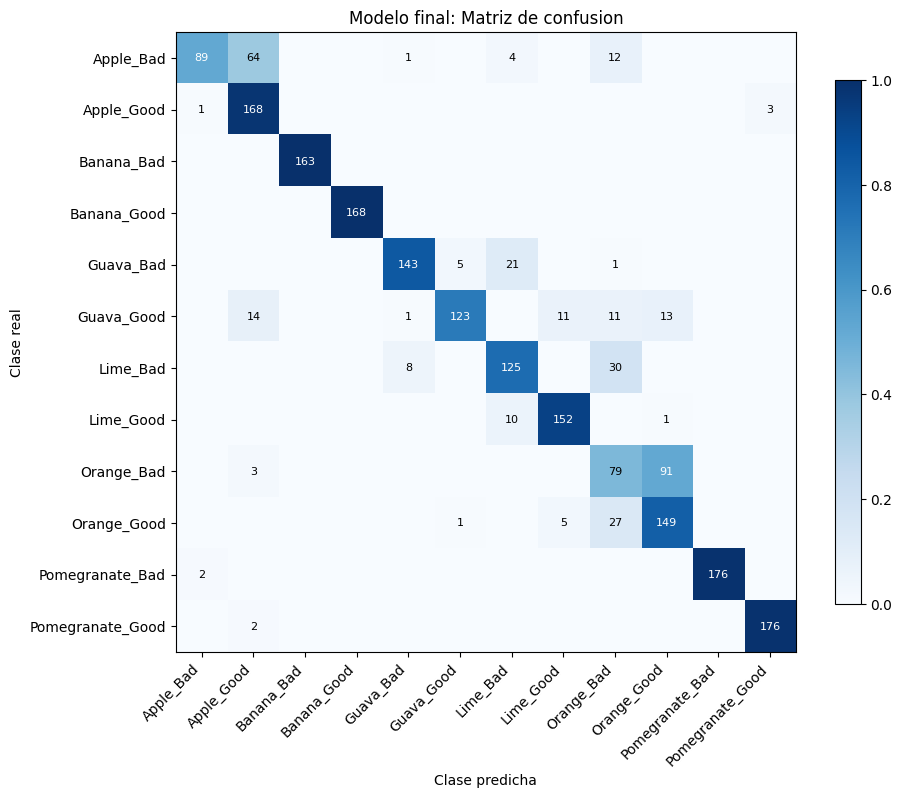

Confusiones mas frecuentes (real, predicha)
        Orange_Bad, Orange_Good       91
         Apple_Bad, Apple_Good        64
          Lime_Bad, Orange_Bad        30
       Orange_Good, Orange_Bad        27
         Guava_Bad, Lime_Bad          21
        Guava_Good, Apple_Good        14
        Guava_Good, Orange_Good       13
         Apple_Bad, Orange_Bad        12

 Errores: 342 de 2053 | de fruta: 143, (129 conservan la calidad) | solo de calidad: 199
Exactitud solo de fruta (6 clases): 0.9303
Exactitud solo de calidad (buena/mala): 0.8962

Confianza promedio en aciertos: 0.958 | en errores: 0.803


In [6]:
fruta = lambda k: class_name[k].split("_")[0]
calidad = lambda k: class_name[k].split("_")[1]

cm = confusion_matrix(y_test, y_pred)
cm_norm = cm/ cm.sum(axis = 1, keepdims=True)

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASES)); ax.set_xticklabels(class_name, rotation = 45, ha= "right")
ax.set_yticks(range(NUM_CLASES)); ax.set_yticklabels(class_name)

for i in range(NUM_CLASES):
  for j in range(NUM_CLASES):
    if cm[i,j]:
      ax.text(j, i, cm[i,j], ha="center", va="center", fontsize=8, color="white" if cm_norm[i, j] > 0.5 else "black")

ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
ax.set_title("Modelo final: Matriz de confusion")
plt.colorbar(im, ax=ax, shrink=0.8); plt.show()

errores = [(cm[i,j], class_name[i], class_name[j]) for i in range(NUM_CLASES) for j in range(NUM_CLASES)  if i != j and cm[i,j] > 0 ]
print("Confusiones mas frecuentes (real, predicha)")
for n, real, pred in sorted(errores, reverse=True)[:8]:
  print(f" {real:>17}, {pred:<17} {n}")

mal = y_test != y_pred
err_fruta = np.array([fruta(a) != fruta(b) for a, b in zip(y_test, y_pred)])
conserva = sum(calidad(a) == calidad(b) for a, b in zip(y_test[err_fruta], y_pred[err_fruta]))
print(f"\n Errores: {mal.sum()} de {len(y_test)} | de fruta: {err_fruta.sum()}, ({conserva} conservan la calidad) | solo de calidad: {mal.sum() - err_fruta.sum()}")

acc_fruta = np.mean([fruta(a) == fruta(b) for a, b in zip(y_test, y_pred)])
acc_calidad = np.mean([calidad(a) == calidad(b) for a, b in zip(y_test, y_pred)])
print(f"Exactitud solo de fruta (6 clases): {acc_fruta:.4f}")
print(f"Exactitud solo de calidad (buena/mala): {acc_calidad:.4f}")

conf = probs_test.max(axis=1)
print(f"\nConfianza promedio en aciertos: {conf[~mal].mean():.3f} | en errores: {conf[mal].mean():.3f}")

In [9]:
splits = pd.read_csv(os.path.join(DATA, 'splits.csv'))
splits['anio'] = 0
con_fecha = splits["timestamp"] <1e12
splits.loc[con_fecha, "anio"] = pd.to_datetime(splits.loc[con_fecha, "timestamp"], unit="s").dt.year
splits["clave"] = splits["clase"] + "/" + splits["archivo"]
info = splits[splits["split"] == "test"].set_index("clave")

In [49]:
def camara(ruta):
  try:
    return Image.open(os.path.join(ORIGEN, ruta)).getexif().get(272) or "Sin EXIF"
  except Exception:
    return "Desconocido"
claves = [os.path.basename(os.path.dirname(p)) + "/" + os.path.basename(p) for p in test_raw.file_paths]
det= pd.DataFrame({
    "clase": [class_name[k] for k in y_test],
    "calidad": [calidad(k) for k in y_test],
    "anio": [int(info.loc[k, "anio"]) for k in claves],
    "camara": [camara(info.loc[k, "ruta"]) for k in claves],
    "acierto": ~mal,
})

det["periodo"] = det["anio"].map({2019: "2019", 2020: "2020"}).fillna("sin fecha")

print("Exactitud por periodo de captura:")
print(det.groupby("periodo")["acierto"].agg(["mean", "size"]).round(3).to_string())
print("\nExactitud por telefono:")
print(det.groupby("camara")["acierto"].agg(["mean", "size"]).round(3).sort_values("mean").to_string())
print("\nExactitud por calidad dentro de 2020:")
print(det[det["periodo"] == "2020"].groupby("calidad")["acierto"].agg(["mean", "size"]).round(3).to_string())


acc_2020 = det.loc[det["periodo"] == "2020", "acierto"].mean()
acc_resto =det.loc[det["periodo"] != "2020", "acierto"].mean()

Exactitud por periodo de captura:
            mean  size
periodo               
2019       0.886  1601
2020       0.616   417
sin fecha  1.000    35

Exactitud por telefono:
               mean  size
camara                   
iPhone SE     0.254   130
realme 5 Pro  0.616   417
Z2 Plus       0.905   813
Sin EXIF      0.978   359
iPhone 6      1.000   254
SM-G950F      1.000    80

Exactitud por calidad dentro de 2020:
          mean  size
calidad             
Bad      0.489   186
Good     0.719   231


In [15]:
capas = [c for c in modelo.layers if not isinstance(c, keras.layers.InputLayer)]
i_base = next(i for i, c in enumerate(capas) if isinstance(c, keras.Model) and 'mobilenet' in c.name.lower())
base = capas[i_base]
normalizacion = next(c for c in capas[:i_base] if isinstance(c, keras.layers.Rescaling))
cabeza = capas[i_base +1:]

In [16]:
def gradcam(img):
  x = normalizacion(tf.convert_to_tensor(img[None], dtype=tf.float32))
  with tf.GradientTape() as tape:
    mapas = base(x, training=False)
    tape.watch(mapas)
    y = mapas
    for capa in cabeza:
      y = capa(y, training =False)
    clase = int(tf.argmax(y[0]))
    puntuaje = y[:, clase]
  grads = tape.gradient(puntuaje, mapas)[0]
  pesos = tf.reduce_mean(grads, axis=(0,1))
  cam = tf.nn.relu(tf.reduce_sum(mapas[0] * pesos, axis=-1)).numpy()
  cam = cam/ (cam.max() +1e-8)
  return cam, clase, y[0].numpy()

In [28]:
def superponer(ax, img, cam, titulo, color):
  mapa = np.array(Image.fromarray(np.uint8(cam*225)).resize(IMG_SIZE, Image.BILINEAR)) / 255.0
  ax.imshow(img.astype("uint8"))
  ax.imshow(mapa, cmap="jet", alpha=0.4)
  ax.set_title(titulo, fontsize=8, color = color); ax.axis("off")

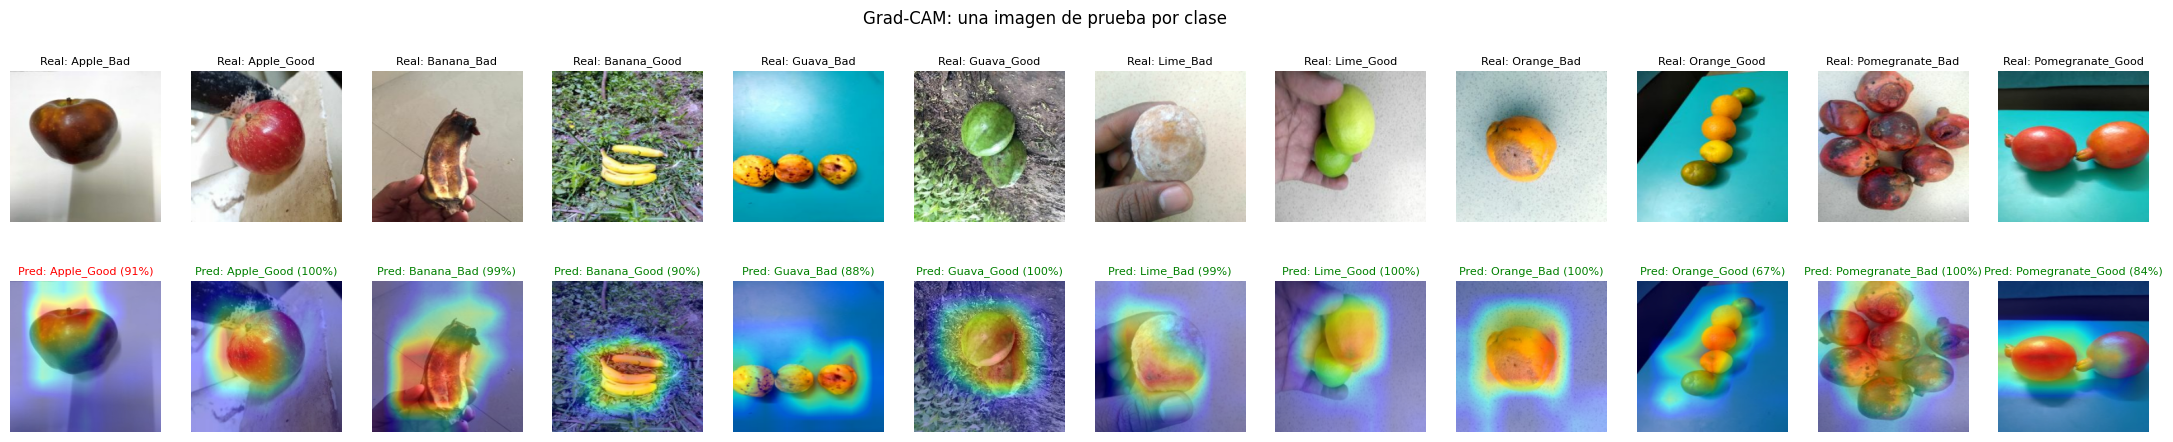

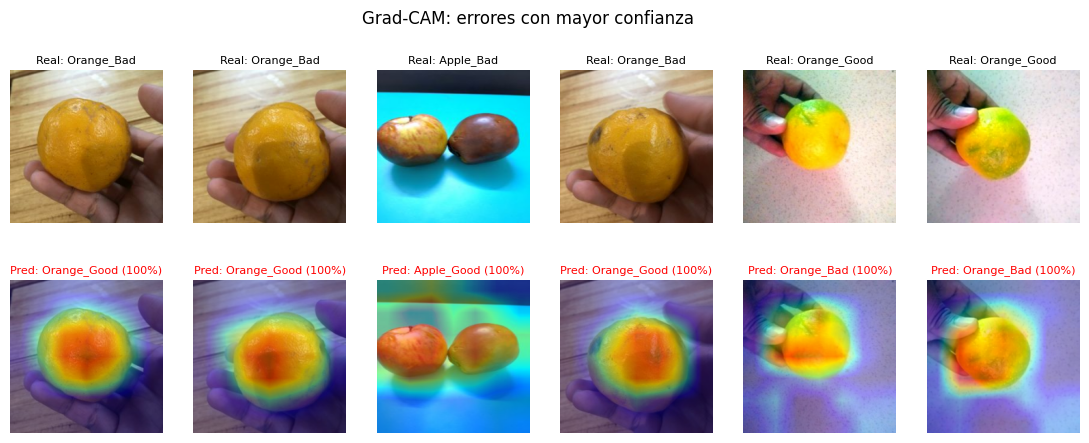

In [29]:
imgs_test = np.concatenate([x.numpy() for x, _ in test_raw])
rng= np.random.default_rng(42)
ejemplos = [rng.choice(np.where(y_test == k)[0]) for k in range(NUM_CLASES)]
errores_conf = np.where(mal)[0][np.argsort(-conf[mal])][:6]


for titulo_fig, indices in [("Grad-CAM: una imagen de prueba por clase", ejemplos),("Grad-CAM: errores con mayor confianza", errores_conf)]:
  fig, axes = plt.subplots(2, len(indices), figsize=(2.3 *len(indices), 5))
  for j, i in enumerate(indices):
    cam, clase, p = gradcam(imgs_test[i])
    ok = clase == y_test[i]
    axes[0, j].imshow(imgs_test[i].astype("uint8")); axes[0, j].axis("off")
    axes[0, j].set_title(f"Real: {class_name[y_test[i]]}", fontsize=8)
    superponer(axes[1, j], imgs_test[i], cam, f"Pred: {class_name[clase]} ({p[clase]:.0%})", "green" if ok else "red" )
  plt.suptitle(titulo_fig); plt.show()

In [30]:
def proporcion_borde(cam):
  centro = cam[2:5, 2:5].sum()
  return 1 - centro / (cam.sum() + 1e-8)

In [32]:
muestra = rng.choice(len(y_test), size=min(400, len(y_test)), replace = False)
bordes = np.array([proporcion_borde(gradcam(imgs_test[i])[0]) for i in muestra])
res_borde = pd.DataFrame({'calidad': [calidad(y_test[i]) for i in muestra], "acierto": ~mal[muestra], "borde": bordes})
print("Proporción promedio de la atención fuera del centro de la imagen (0–1):")
print(res_borde.groupby(["calidad", "acierto"])["borde"].agg(["mean", "size"]).round(3).to_string())

Proporción promedio de la atención fuera del centro de la imagen (0–1):
                  mean  size
calidad acierto             
Bad     False    0.602    50
        True     0.572   149
Good    False    0.618    25
        True     0.526   176


In [37]:
carpeta_mixta = os.path.join(ORIGEN, "Mixed Qualit_Fruits")
nombre_fruta = {"Lemon": "Lime"}

filas_mix, imgs_mix = [], []
for sub in sorted(os.listdir(carpeta_mixta)):
  for f in sorted(os.listdir(os.path.join(carpeta_mixta, sub))):
    img = keras.utils.load_img(os.path.join(carpeta_mixta, sub, f), target_size=IMG_SIZE, interpolation="bilinear")
    imgs_mix.append(np.asarray(img, dtype="float32"))
    filas_mix.append(nombre_fruta.get(sub,sub))
imgs_mix = np.stack(imgs_mix)
p_mix = modelo.predict(imgs_mix, batch_size=BATCH_SIZE, verbose =0)
pred_mix = np.argmax(p_mix, axis=1)

In [38]:
mix = pd.DataFrame({"fruta_real": filas_mix, "fruta_pred": [fruta(k) for k in pred_mix], "calidad_pred": [calidad(k) for k in pred_mix], "confianza": p_mix.max(axis=1)})
mix["fruta_ok"] = mix["fruta_real"] == mix["fruta_pred"]
print(f"Imagenes mixtas: {len(mix)} | fruta correcta: {mix['fruta_ok'].mean():.3f}")
print(f"Confianza promedio: mixtas {mix['confianza'].mean():.3f} vs. prueba {conf.mean():.3f}\n")
print(pd.crosstab(mix["fruta_real"], mix["calidad_pred"], margins=True).to_string())

Imagenes mixtas: 1074 | fruta correcta: 0.648
Confianza promedio: mixtas 0.790 vs. prueba 0.932

calidad_pred  Bad  Good   All
fruta_real                   
Apple          13   100   113
Banana        115   170   285
Guava          79    69   148
Lime           38   240   278
Orange         23   102   125
Pomegranate    35    90   125
All           303   771  1074


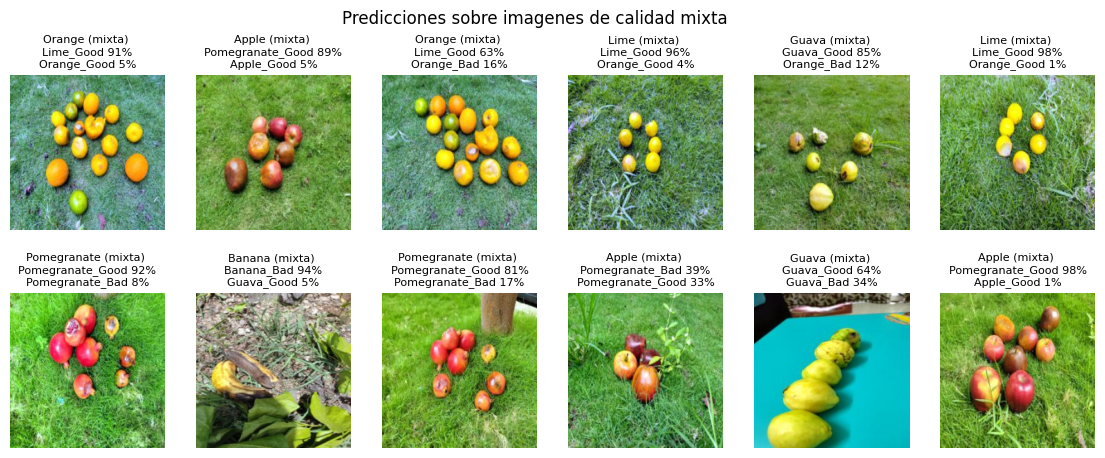

In [42]:
fig, axes = plt.subplots(2, 6, figsize=(14,5.2))
for ax, i in zip(axes.ravel(), rng.choice(len(mix), size=12, replace=False)):
  ax.imshow(imgs_mix[i].astype("uint8")); ax.axis("off")
  top = np.argsort(-p_mix[i])[:2]
  ax.set_title(f"{mix["fruta_real"][i]} (mixta) \n" + "\n".join(f"{class_name[k]} {p_mix[i][k]:.0%}" for k in top), fontsize=8)
plt.suptitle("Predicciones sobre imagenes de calidad mixta"); plt.show()

In [43]:
resultado_final = {
    "modelo": os.path.basename(ruta_modelo),
    "test_acc": round(float(test_acc), 4),
    "test_loss": round(float(test_loss), 4),
    "test_f1_macro": round(float(f1_score(y_test, y_pred, average="macro")), 4),
    "errores": int(mal.sum()), "errores_fruta": int(err_fruta.sum()),
    "acc_fruta": round(float(acc_fruta), 4), "acc_calidad": round(float(acc_calidad), 4),
    "acc_2020": round(float(acc_2020), 4), "acc_resto": round(float(acc_resto), 4),
    "mixtas_fruta_correcta": round(float(mix["fruta_ok"].mean()), 4),
}
with open(os.path.join(RESULTADOS, "resultado_final_test.json"), "w") as f:
    json.dump(resultado_final, f, indent=2)
print(json.dumps(resultado_final, indent=2))

{
  "modelo": "modelo_E5_Finetunning.keras",
  "test_acc": 0.8334,
  "test_loss": 0.6364,
  "test_f1_macro": 0.8337,
  "errores": 342,
  "errores_fruta": 143,
  "acc_fruta": 0.9303,
  "acc_calidad": 0.8962,
  "acc_2020": 0.6163,
  "acc_resto": 0.8888,
  "mixtas_fruta_correcta": 0.648
}


In [45]:
def predecir(ruta, top=3):
  img= keras.utils.load_img(ruta, target_size=IMG_SIZE, interpolation="bilinear")
  x = np.asarray(img, dtype="float32")[None]
  p = modelo.predict(x, verbose=0)[0]
  print(f"\n{os.path.basename(ruta)}")
  for k in np.argsort(-p)[:top]:
    fruta_k, calidad_k = class_name[k].split("_")
    print(f" {fruta_k:<12} {'buena' if calidad_k == "Good" else "mala":<6} {p[k]:6.1%}")
  return class_name[int(np.argmax(p))], float(p.max())

for ruta in rng.choice(test_raw.file_paths, size=4, replace=False):
  predecir(ruta)


IMG_7923.JPG
 Banana       mala    99.9%
 Banana       buena    0.1%
 Guava        buena    0.0%

IMG_20190923_181759.jpg
 Orange       mala    99.9%
 Lime         mala     0.1%
 Orange       buena    0.0%

20190820_143635.jpg
 Pomegranate  buena   98.9%
 Apple        buena    0.7%
 Apple        mala     0.3%

IMG_20190824_180820.jpg
 Pomegranate  mala    99.9%
 Apple        mala     0.1%
 Pomegranate  buena    0.0%


In [48]:
!pip install -q gradio
import gradio as gr

def predecir_interfaz(img):
  if img is None:
    return{}
  x = np.asarray(Image.fromarray(img).convert("RGB").resize(IMG_SIZE, Image.BILINEAR), dtype="float32")[None]
  p = modelo.predict(x, verbose=0)[0]
  etiqueta = lambda c: f"{c.split('_')[0]} x {'buena calidad' if c.endswith('Good') else 'Mala calidad'}"
  return {etiqueta(class_name[k]): float(p[k]) for k in range(NUM_CLASES)}

demo = gr.Interface(
    fn = predecir_interfaz,
    inputs = gr.Image(label = "Foto de la fruta"),
    outputs= gr.Label(num_top_classes=3, label="Predicciones"),
    title = "Clasificacion de la calidad de frutas",
    description="Manzana, platano, guayaba, lima, naranja o granada. El modelo indica la fruta y si su calidad es buena o mala",
    flagging_mode="never",
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://211da00d8b633f561b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
